# Multiclass Logistic Regression

## Which drink matches the ingredients?

Sugar and caffeine offer clues about a drink, but neither feature identifies its type alone. This synthetic cafe dataset has three labels: tea, coffee, and cocoa. Sugar is measured in grams and caffeine in milligrams.

Multiclass logistic regression learns a separate linear score for each class. Softmax converts the scores into probabilities that sum to one. The class with the largest probability becomes the prediction.

> Sugar and caffeine → one score per class → softmax probabilities → most probable class

<img src="https://raw.githubusercontent.com/sonamu-jun/introduction-to-ai-convergence/main/07-1_Classification/assets/03_softmax_probabilities.png" alt="The same sugar and caffeine values produce three softmax probabilities. The largest probability determines the predicted drink." width="640" style="max-width:100%;height:auto;">

One-hot encoding represents a known class with a one at its position and zeros elsewhere. With classes ordered as tea, coffee, cocoa, a coffee label becomes `[0, 1, 0]`. Cross-entropy encourages the model to assign more probability to that recorded class. The model itself can output probabilities such as 0.2, 0.7, and 0.1 rather than a one-hot vector.


## A boundary between three choices

Gradient descent fits the class coefficients using training drinks. The code standardizes both inputs using training means and scales, so their different units do not dominate the updates. Validation drinks are excluded from both scaling and fitting.

The controls describe a new drink. The star marks its inputs, the background shows the model's predicted classes, and the colored points are training drinks with their recorded labels. The three displayed probabilities and the background come from the same fitted model.

Changing one input moves the star while keeping the other input fixed. Crossing a decision boundary changes the winning class, even though the probabilities vary smoothly. Softmax probabilities compete: increasing one class's share reduces the total share available to the others.


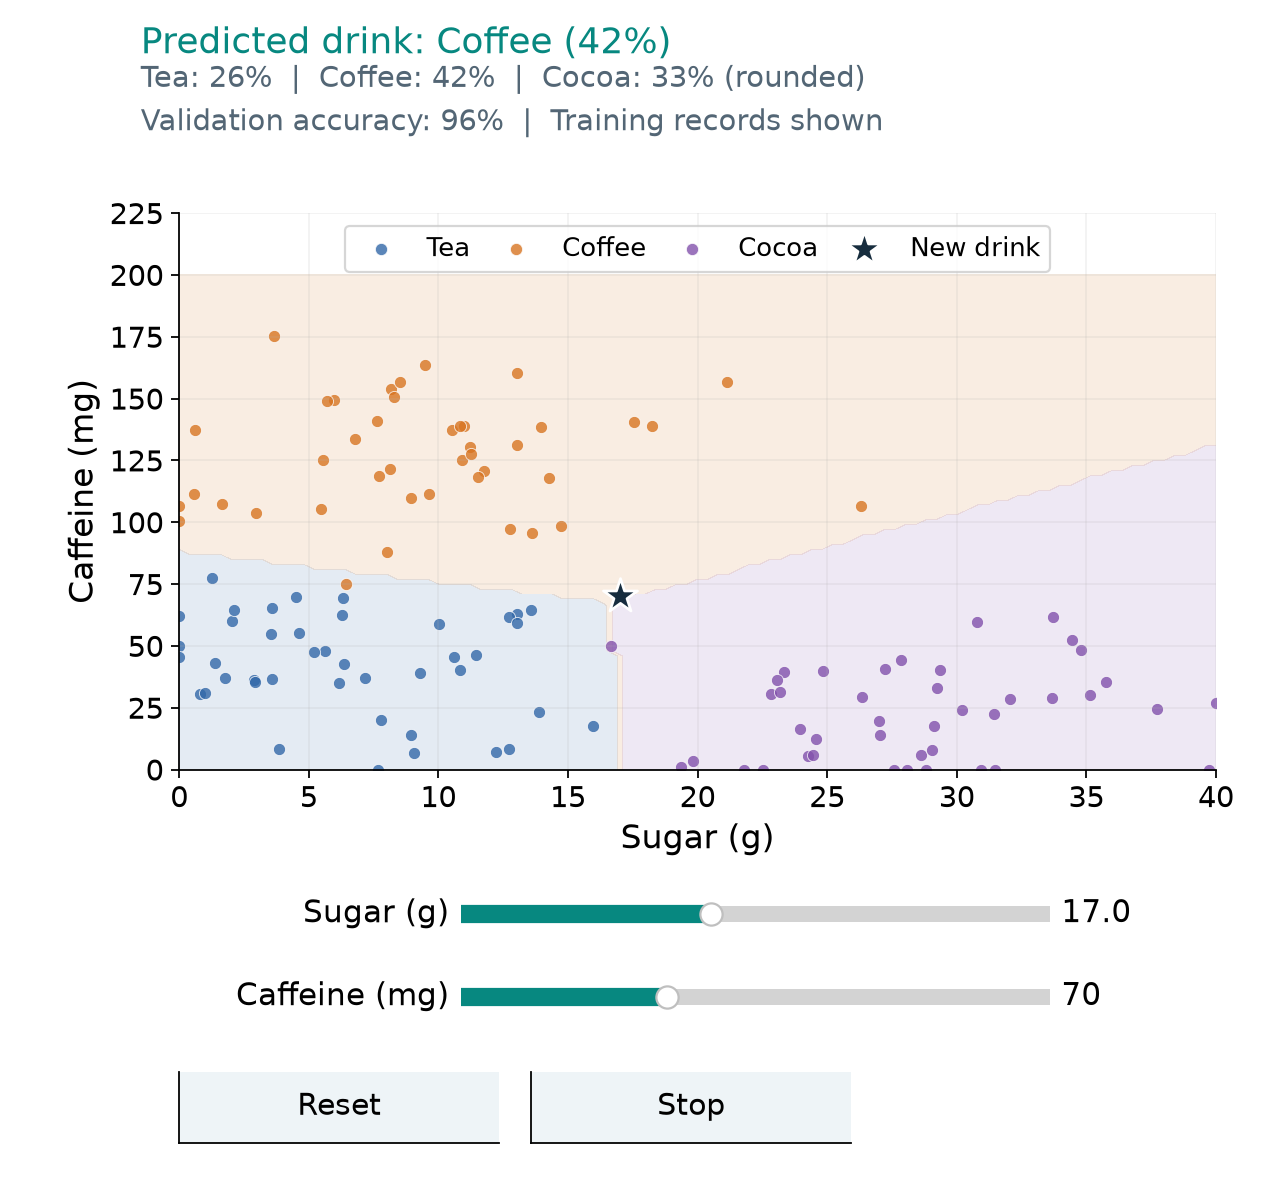

In [1]:
import os
import sys
import io
import numpy as np
import matplotlib

CLASSIFICATION_STATIC = os.environ.get("CLASSIFICATION_STATIC") == "1"
CLASSIFICATION_BROWSER = sys.platform == "emscripten"
if not CLASSIFICATION_STATIC and not CLASSIFICATION_BROWSER:
    from IPython import get_ipython
    shell = get_ipython()
    if shell is not None and getattr(shell, "kernel", None) is not None:
        shell.run_line_magic("matplotlib", "widget")

import matplotlib.pyplot as plt
from matplotlib.widgets import Slider, Button
from matplotlib.colors import ListedColormap
from IPython.display import Image, display
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

plt.rcParams.update({
    "font.size": 15, "axes.labelsize": 15,
    "xtick.labelsize": 13, "ytick.labelsize": 13, "legend.fontsize": 12,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": .16, "lines.linewidth": 2.5,
    "axes.unicode_minus": False, "figure.facecolor": "white",
})
BLUE, TEAL, ORANGE, PURPLE = "#3268a8", "#078880", "#d87522", "#8251ac"


def sigmoid(score):
    score = np.clip(np.asarray(score, dtype=float), -500, 500)
    return 1 / (1 + np.exp(-score))


def softmax(scores):
    scores = np.asarray(scores, dtype=float)
    weights = np.exp(scores - scores.max(axis=-1, keepdims=True))
    return weights / weights.sum(axis=-1, keepdims=True)


def binary_loss(labels, scores):
    # The logaddexp form avoids taking log(0) at extreme scores.
    return float(np.mean(np.logaddexp(0, scores) - labels * scores))


def classification_metrics(observed, predicted):
    observed, predicted = np.asarray(observed), np.asarray(predicted)
    tp = int(np.sum((observed == 1) & (predicted == 1)))
    tn = int(np.sum((observed == 0) & (predicted == 0)))
    fp = int(np.sum((observed == 0) & (predicted == 1)))
    fn = int(np.sum((observed == 1) & (predicted == 0)))
    return {"TP": tp, "TN": tn, "FP": fp, "FN": fn,
            "accuracy": (tp + tn) / len(observed),
            "precision": tp / (tp + fp) if tp + fp else np.nan,
            "recall": tp / (tp + fn) if tp + fn else np.nan,
            "F1": 2 * tp / (2 * tp + fp + fn) if 2 * tp + fp + fn else np.nan}


def percent(value):
    return "undefined" if not np.isfinite(value) else f"{value:.0%}"


# A rerun releases the previous figure and its input callbacks first.
for _previous_view in globals().get("_classification_views", {}).values():
    _previous_view.close()
_classification_views = {}


class ClassificationExplorer:
    """One figure keeps the selected model, predictions and scores together."""

    def __init__(self, name, render, sliders, actions=()):
        self.render = render
        self.slider_specs = sliders
        self.controls, self.buttons, self.state = {}, {}, {}
        self.stopped = False
        self.defaults = {key: initial for key, label, low, high, initial, step, fmt in sliders}
        with plt.ioff():
            self.figure = plt.figure(figsize=(8, 8.0 if len(sliders) == 3 else 7.4), dpi=80)
        self.status = self.figure.text(.11, .955, "", fontsize=16, color=TEAL)
        self.detail = self.figure.text(.11, .89, "", fontsize=13, color="#536675", linespacing=1.5)
        bottom = .28 + .07 * (len(sliders) - 1)
        self.ax = self.figure.add_axes([.14, bottom, .81, .82 - bottom])
        for i, (key, label, low, high, initial, step, fmt) in enumerate(sliders):
            y = .145 + .07 * (len(sliders) - i - 1)
            slider = Slider(self.figure.add_axes([.36, y, .46, .026]),
                            label, low, high, valinit=initial, valstep=step,
                            valfmt=fmt, color=TEAL)
            slider.label.set_fontsize(14)
            slider.valtext.set_fontsize(14)
            slider.on_changed(self.update)
            self.controls[key] = slider
        commands = list(actions) + [("Reset", lambda view: view.reset()),
                                    ("Stop", lambda view: view.stop())]
        self.commands = commands
        width = min(.25, .83 / len(commands) - .025)
        for i, (label, callback) in enumerate(commands):
            button = Button(self.figure.add_axes([.14 + i * (width + .025), .035, width, .06]),
                            label, color="#eef4f7", hovercolor="#d7e9e6")
            button.label.set_fontsize(13.5)
            button.on_clicked(lambda event, cb=callback: cb(self) if not self.stopped else None)
            self.buttons[label] = button
        self.figure.canvas.mpl_connect("close_event", lambda event: self.stop())
        _classification_views[name] = self
        self.update()

    def update(self, _=None):
        if self.stopped:
            return
        self.ax.clear()
        self.state = self.render(self, **{key: slider.val for key, slider in self.controls.items()})
        self.figure.canvas.draw_idle()
        self.refresh_local()

    def set_values(self, **values):
        if self.stopped:
            return
        for key, value in values.items():
            slider = self.controls[key]
            events, drawing = slider.eventson, slider.drawon
            slider.eventson = slider.drawon = False
            slider.set_val(value)
            slider.eventson, slider.drawon = events, drawing
        self.update()

    def reset(self):
        self.set_values(**self.defaults)

    def refresh_local(self):
        if not hasattr(self, "local_image"):
            return
        from matplotlib.transforms import Bbox
        width, height = self.figure.get_size_inches()
        # Crop only the embedded Matplotlib controls; native widgets follow the chart.
        lower = max(0, self.ax.get_position().y0 - .09) * height
        buffer = io.BytesIO()
        self.figure.savefig(buffer, format="png", dpi=80, facecolor="white",
                            bbox_inches=Bbox.from_extents(0, lower, width, height))
        self.local_image.value = buffer.getvalue()
        self.syncing_local = True
        for key, control in self.local_controls.items():
            control.value = self.controls[key].val
        self.syncing_local = False

    def start_local(self):
        from ipywidgets import Image as WidgetImage, FloatSlider, IntSlider
        from ipywidgets import Button as WidgetButton, HBox, VBox, Layout
        self.syncing_local = False
        self.local_image = WidgetImage(format="png", layout=Layout(
            width="100%", max_width="640px", height="auto"))
        self.local_controls, self.local_buttons = {}, {}
        for key, label, low, high, initial, step, fmt in self.slider_specs:
            slider_type = IntSlider if fmt == "%0.0f" and step == 1 else FloatSlider
            control = slider_type(value=initial, min=low, max=high, step=step,
                                  description=label, readout_format=fmt.replace("%0", ""),
                                  continuous_update=True,
                                  style={"description_width": "120px"},
                                  layout=Layout(width="100%", max_width="640px"))
            def changed(change, key=key):
                if not self.syncing_local and not self.stopped:
                    self.controls[key].set_val(change["new"])
            control.observe(changed, names="value")
            self.local_controls[key] = control
        for label, callback in self.commands:
            button = WidgetButton(description=label, layout=Layout(
                flex="1 1 0", min_width="120px", height="34px", margin="2px"))
            button.on_click(lambda _, cb=callback: cb(self) if not self.stopped else None)
            self.local_buttons[label] = button
        row = HBox(list(self.local_buttons.values()), layout=Layout(width="100%", flex_flow="row wrap"))
        self.local_row = row
        self.local_output = VBox([self.local_image, *self.local_controls.values(), row],
                                layout=Layout(width="100%", max_width="640px"))
        self.refresh_local()
        display(self.local_output)

    def start(self):
        if CLASSIFICATION_STATIC:
            buffer = io.BytesIO()
            self.figure.savefig(buffer, format="png", dpi=160, facecolor="white")
            display(Image(data=buffer.getvalue(), width=640,
                          alt=self.status.get_text() + ". " + self.detail.get_text()))
            plt.close(self.figure)
        elif CLASSIFICATION_BROWSER:
            # JSPCV sends mouse events after this cell has returned.
            plt.show(block=False)
        elif hasattr(self.figure.canvas, "toolbar_visible"):
            # The ipympl figure supplies a responsive chart with native widget controls.
            self.start_local()
        else:
            plt.show(block=False)

    def stop(self):
        if self.stopped:
            return
        self.stopped = True
        for control in list(self.controls.values()) + list(self.buttons.values()):
            control.set_active(False)
        for control in [*getattr(self, "local_controls", {}).values(),
                        *getattr(self, "local_buttons", {}).values()]:
            control.disabled = True
        if hasattr(self, "local_buttons"):
            self.local_buttons["Stop"].description = "Stopped"
        self.buttons["Stop"].label.set_text("Stopped")
        self.figure.canvas.draw_idle()

    def close(self):
        self.stop()
        for control in list(self.controls.values()) + list(self.buttons.values()):
            control.disconnect_events()
        plt.close(self.figure)
        if hasattr(self, "local_output"):
            self.local_output.close()
            self.local_image.close()
            self.local_row.close()
            for control in [*self.local_controls.values(), *self.local_buttons.values()]:
                control.close()

rng = np.random.default_rng(71)
class_names = np.array(["Tea", "Coffee", "Cocoa"])
class_colors = [BLUE, ORANGE, PURPLE]
centers = np.array([[7, 45], [10, 135], [28, 25]])
labels = np.repeat(np.arange(3), 60)
drinks = centers[labels] + rng.normal(size=(len(labels), 2)) * [6, 27]
drinks = np.clip(drinks, [0, 0], [40, 200])
train_id, validation_id = train_test_split(np.arange(len(labels)), test_size=.3,
                                         stratify=labels, random_state=71)
feature_mean, feature_scale = drinks[train_id].mean(axis=0), drinks[train_id].std(axis=0)


def drink_features(values):
    values = np.atleast_2d(values)
    return np.column_stack([np.ones(len(values)), (values - feature_mean) / feature_scale])


train_features = drink_features(drinks[train_id])
one_hot = np.eye(3)[labels[train_id]]
weights = np.zeros((3, 3))
for iteration in range(2500):
    probability = softmax(train_features @ weights)
    weights -= .15 * train_features.T @ (probability - one_hot) / len(train_id)
validation_probability = softmax(drink_features(drinks[validation_id]) @ weights)
validation_accuracy = np.mean(validation_probability.argmax(axis=1) == labels[validation_id])
sugar_grid, caffeine_grid = np.meshgrid(np.linspace(0, 40, 101), np.linspace(0, 200, 101))
region_probability = softmax(drink_features(np.c_[sugar_grid.ravel(), caffeine_grid.ravel()]) @ weights)
regions = region_probability.argmax(axis=1).reshape(sugar_grid.shape)


def render_drink(view, sugar, caffeine):
    probability = softmax(drink_features([[sugar, caffeine]]) @ weights)[0]
    predicted = int(probability.argmax())
    ax = view.ax
    ax.contourf(sugar_grid, caffeine_grid, regions, levels=[-.5, .5, 1.5, 2.5],
                colors=class_colors, alpha=.13)
    for index, (name, color) in enumerate(zip(class_names, class_colors)):
        selected = train_id[labels[train_id] == index]
        ax.scatter(drinks[selected, 0], drinks[selected, 1], color=color, s=30,
                   edgecolor="white", linewidth=.4, label=name, alpha=.8)
    ax.scatter([sugar], [caffeine], color="#172d3e", marker="*", s=260,
               edgecolor="white", linewidth=1.2, zorder=5, label="New drink")
    ax.set(xlim=(0, 40), ylim=(0, 225), xlabel="Sugar (g)", ylabel="Caffeine (mg)")
    ax.legend(loc="upper center", ncol=4, fontsize=11.5, columnspacing=.8)
    view.status.set_text(f"Predicted drink: {class_names[predicted]} ({probability[predicted]:.0%})")
    view.detail.set_text("  |  ".join(f"{name}: {p:.0%}" for name, p in zip(class_names, probability))
                         + f" (rounded)\nValidation accuracy: {validation_accuracy:.0%}  |  Training records shown")
    return {"probability": probability, "prediction": predicted, "query": np.array([sugar, caffeine])}


drink_demo = ClassificationExplorer("drink", render_drink, [
    ("sugar", "Sugar (g)", 0, 40, 17, .5, "%0.1f"),
    ("caffeine", "Caffeine (mg)", 0, 200, 70, 5, "%0.0f"),
])
drink_demo.start()


## The largest probability can still be small

A winning class with only a small lead is an ambiguous prediction. Softmax always selects among the available classes; it has no automatic label for an unfamiliar drink. A new recipe can therefore receive a confident but incorrect label.

The reported validation accuracy checks the fixed model on separate simulated drinks. It does not measure probability calibration or establish performance at a real cafe. Sugar and caffeine also leave out ingredients that may distinguish otherwise similar drinks.
